# 1 — Everything observed: train and infer on one graph

The simplest workflow. Every grid point has features, so nothing is withheld:

- `build_graph(positions, features)` returns a `Data` with **no** `input_mask`, `output_mask` or
  `y`.
- `train` scores every row. The internal train/validation split chooses which rows enter the
  objective; it never hides neighbours.
- `embed` returns exactly `num_nodes` rows.

This is the baseline the other two notebooks build on.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import numpy as np
import torch
from scipy.spatial import cKDTree

from nofe import NOFE, build_graph
from nofe.affinity import affinity_kl_loss

# Resolve paths from the repository layout, not the process cwd: VS Code always starts kernels in
# the workspace folder (`jupyter.notebookFileRoot` is ignored since 2024.4), while `_execute.py`
# runs from `notebooks/`. Walk up from the cwd looking for the repo root, so both agree.
REPO = next(
    (
        ancestor
        for ancestor in (Path.cwd(), *Path.cwd().parents)
        if (ancestor / "pyproject.toml").is_file()
    ),
    None,
)
if REPO is None:
    raise RuntimeError(f"run this notebook from inside the nofe checkout, not {Path.cwd()}")
NOTEBOOKS = REPO / "notebooks"
DATA = NOTEBOOKS / "data"

# The example data is not in Git (21 MB per date), so fail with the fetch command rather than the
# opaque `StopIteration`/`FileNotFoundError` the loader would otherwise raise.
if not (DATA / "2018-01-01.nc").exists():
    raise FileNotFoundError(
        f"missing {DATA / '2018-01-01.nc'}\n"
        "The ERA5 inputs are not committed. Fetch them once with:\n"
        f"  mkdir -p {DATA}\n"
        f"  cp /Volumes/T7-storage/ERA5/data/2018-01-0{{1,2}}.nc {DATA}/"
    )

# The notebooks import the ERA5 helpers straight from the example script, so the loader and the
# globe plot have exactly one implementation in the repo. `era5` is imported after `sys.path` is
# extended, which is why the noqa marker below is needed.
sys.path.insert(0, str(REPO / "examples"))
import era5  # noqa: E402


def kl(on, embedding) -> float:
    """Mean KL between a graph's own feature affinities and an embedding of its rows."""
    return float(affinity_kl_loss(on.x, embedding, on.edge_index, on.num_nodes))


def pca_baseline(data, dims: int = 3) -> torch.Tensor:
    """Best linear projection to ``dims`` dimensions: the reference the model has to beat."""
    centred = data.x - data.x.mean(dim=0, keepdim=True)
    _, _, basis = torch.linalg.svd(centred, full_matrices=False)
    return centred @ basis[:dims].T


def knn_agreement(reference: torch.Tensor, candidate: torch.Tensor, k: int = 10) -> float:
    """Mean share of exact k-nearest neighbours two point sets have in common."""
    ref = reference.detach().cpu().numpy()
    cand = candidate.detach().cpu().numpy()
    _, ref_nn = cKDTree(ref).query(ref, k=k + 1)
    _, cand_nn = cKDTree(cand).query(cand, k=k + 1)
    shared = [len(set(a) & set(b)) / k for a, b in zip(ref_nn[:, 1:], cand_nn[:, 1:], strict=True)]
    return float(np.mean(shared))


def close(a: torch.Tensor, b: torch.Tensor, rtol: float = 1e-4) -> bool:
    """Relative agreement in units of the embedding's own scale."""
    return bool((a - b).abs().max() <= rtol * a.abs().max())


print("nofe ready; the faiss fallback warning is expected on macOS arm64")


/Users/laueb4818/github/NOFE-pkg/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


nofe ready; the faiss fallback warning is expected on macOS arm64


/Users/laueb4818/github/NOFE-pkg/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Load one date at coarse resolution

`era5.load_fields` standardises each variable per field and drops the two duplicated pole rows;
`era5.unit_sphere` turns lat/lon into 3-D unit vectors, so the ±180° seam and the poles are
ordinary neighbours for the kNN graph.

In [2]:
# STRIDE=8 is the whole globe at 89 x 180 = 16,020 grid points. Lower the stride for a finer
# grid (4 gives 64,440 nodes, 2 gives the full 258,480-node field).
STRIDE = 8
features, latitudes, longitudes = era5.load_fields(DATA / "2018-01-01.nc", stride=STRIDE)
positions = era5.unit_sphere(latitudes, longitudes)
flat = features.reshape(-1, features.shape[2])
print(
    f"grid {features.shape[0]}x{features.shape[1]} -> {positions.shape[0]} nodes, "
    f"{flat.shape[1]} variables each"
)


grid 89x180 -> 16020 nodes, 11 variables each


## Build the graph

`neighbor="knn", k=10` matches the ERA5 example. Edges are built once, here; the operator only
consumes `edge_index`/`edge_attr`, so a radius neighbourhood works identically
(`neighbor="radius", radius=0.05` on the unit sphere).

In [3]:
data = build_graph(positions, flat, neighbor="knn", k=era5.K)
print(data)
print(
    "masks:",
    getattr(data, "input_mask", None),
    getattr(data, "output_mask", None),
    "| truth in y:",
    getattr(data, "y", None) is not None,
)
print(
    "every node both sends and receives:",
    set(data.edge_index[0].tolist()) == set(range(data.num_nodes)),
)


Data(x=[16020, 11], edge_index=[2, 160200], edge_attr=[160200, 7], pos=[16020, 3])
masks: None None | truth in y: False
every node both sends and receives: True


/Users/laueb4818/github/NOFE-pkg/src/nofe/graphs.py:196: RuntimeWarning: faiss-cpu is installed but the process maps two OpenMP runtimes, so its parallel search would abort; falling back to scipy cKDTree, which is much slower for kNN search on large point sets. Install nofe's faiss-cpu dependency to silence this warning.
  neighbor, query = _pairs(points, src_ids, dst_ids, radius=radius, k=k)


## Train

`width=8, ker_width=32` are the reference ERA5 settings: `NNConv` materialises an
`[num_edges, width]` message tensor, so width drives memory. 200 epochs at this resolution takes
well under a minute on an M-series GPU; `verbose=True, log_every=50` prints progress and the final
epoch always prints.

In [4]:
CONFIG = {
    "width": 8,
    "ker_width": 32,
    "epochs": 200,
    "seed": 0,
    "early_stopping": False,
    "verbose": True,
    "log_every": 50,
}

model = NOFE(dim=3, config=CONFIG)
history = model.train(data)
print(
    f"loss {history[0]['train_loss']:.5f} -> {history[-1]['train_loss']:.6f} "
    f"| best val {model.best_val_loss:.6f}"
)


epoch   50/200  train 0.024052  val 0.023836


epoch  100/200  train 0.015813  val 0.015389


epoch  150/200  train 0.015004  val 0.014653


epoch  200/200  train 0.014532  val 0.014409
loss 0.12680 -> 0.014532 | best val 0.014409


## Infer on the same data

`embed` returns one row per `output_mask` node — here every node — in node order (lat-major,
matching the raster). `loss` is the mean KL over the same rows.

In [5]:
embedding = model.embed(data)
print(
    "embedding:",
    tuple(embedding.shape),
    "| device:",
    embedding.device.type,
    "| dtype:",
    embedding.dtype,
)
print(f"mean KL on the training graph: {model.loss(data):.6f}")
assert embedding.shape == (data.num_nodes, 3)
assert torch.isfinite(embedding).all()


embedding: (16020, 3) | device: cpu | dtype: torch.float32
mean KL on the training graph: 0.014512


## Compare against the linear baseline

### How to read the score

The objective is the KL between the graph's feature affinities and the embedding's. It only ranks
a node's 10 graph neighbours relative to each other, so **exact** 10-NN set overlap is a weak proxy:
the 11 variables are close to isotropic (the top three principal components carry only 54% of the
variance), so no 3-D map can reproduce the 11-D neighbour sets exactly.

`pca_baseline` gives the honest reference — the best *linear* projection to 3 dimensions. A useful
embedding beats it on the objective.

In [6]:
reference = pca_baseline(data, dims=3)
print(f"PCA-3 KL: {kl(data, reference):.6f}  |  10-NN {knn_agreement(data.x, reference):.3f}")
print(f"NOFE  KL: {kl(data, embedding):.6f}  |  10-NN {knn_agreement(data.x, embedding):.3f}")
assert kl(data, embedding) < kl(data, reference), "the model should beat linear PCA"
print("the trained operator beats the best linear projection: True")


PCA-3 KL: 0.054847  |  10-NN 0.117


NOFE  KL: 0.014512  |  10-NN 0.064
the trained operator beats the best linear projection: True


## Plot the embedding as an RGB globe

R/G/B are the three embedding dimensions, one `pcolormesh` quad per grid point. Each channel is
centred and scaled by its 5th/95th percentile spread (`era5.PERCENTILE`), so one extreme cyclone
cannot flatten the whole field to grey.

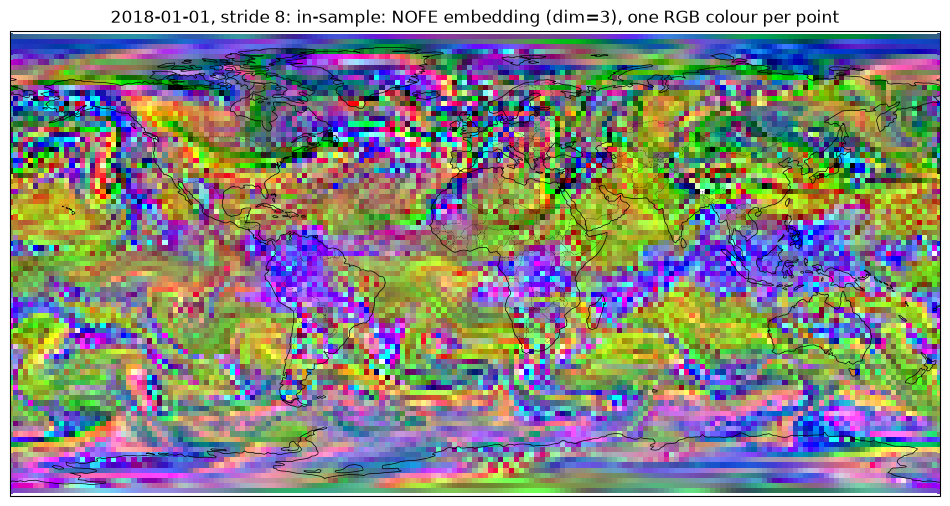

In [7]:
import matplotlib.pyplot as plt

figure = era5.globe_figure(
    latitudes, longitudes, embedding.numpy(), f"2018-01-01, stride {STRIDE}: in-sample"
)
plt.show()


## Save and reload

Checkpoints are self-describing (`nofe-checkpoint-2`): dim, config, model config, weights and the
best validation loss. Reloading reproduces the embedding to floating-point tolerance.

On MPS the comparison is *not* bit-exact: repeating the same forward pass twice already differs by
~4e-6 (measured here), and reloading adds ~6e-6, on embeddings whose magnitude is ~20. That is
Metal kernel scheduling, not a checkpoint defect — `device="cpu"` reproduces bit-identically. The
assertion below uses a relative tolerance for that reason.

In [8]:
path = model.save("in_sample.pt")
restored = NOFE.load(path)
rebuilt = restored.embed(data)
print(
    f"restore max abs diff: {(rebuilt - embedding).abs().max():.2e}"
    f" on a scale of {embedding.abs().max():.1f}"
)
assert close(embedding, rebuilt), "reload must reproduce the embedding"
print("round trip reproducible within relative tolerance: True")
path.unlink()


restore max abs diff: 3.81e-06 on a scale of 22.5
round trip reproducible within relative tolerance: True


## Takeaways

|Fact|Why it matters|
|---|---|
|No `input_mask`, no `y`|A fully observed graph needs neither; `embed` covers every node|
|`embed` returns `num_nodes` rows|Default `output_mask` is every node|
|One graph, one pass|The dense operator sees the entire edge set on every epoch|

Next: **2-held-out-training.ipynb** withholds part of the same date and trains on a merged graph.